# Micrograd from Scratch: Revision Notebook

(Karpathy's micrograd lecture) restructured **bottom-up** into 9 named subsystems.
Every part follows the same order: **ELI5 intuition → math → code → verification → gotchas**.

* Run with *Kernel → Restart & Run All*. It runs top to bottom with no manual ordering (the original didn't, see Part 10).
* `graphviz` and `torch` are optional. If missing, the cells fall back to text output.
* Every number quoted in a markdown cell was produced by running the code in this notebook.

| # | Subsystem | One-line job | Key formula |
|---|-----------|--------------|-------------|
| 1 | Slope | How much does `f` change if `x` changes a hair? | $f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}$ |
| 2 | Partial derivatives | Same idea with many inputs, one at a time | $\frac{\partial d}{\partial a},\frac{\partial d}{\partial b},\frac{\partial d}{\partial c}$ |
| 3 | `Value` | A number that remembers its parents and its local slope | local slope $\times$ upstream grad |
| 4 | Graph + chain rule | Multiply local slopes along the path back to an input | $\frac{\partial L}{\partial a}=\frac{\partial L}{\partial d}\frac{\partial d}{\partial e}\frac{\partial e}{\partial a}$ |
| 5 | Neuron (tanh) | Weighted sum + bias, squashed into $(-1,1)$ | $o=\tanh(\sum_i w_ix_i+b)$ |
| 6 | Automatic `backward()` | Visit nodes in reverse order, *add up* blame | topological sort + `+=` |
| 7 | tanh via exp, PyTorch | Prove the engine composes and matches a real library | $\tanh n=\frac{e^{2n}-1}{e^{2n}+1}$ |
| 8 | Neuron / Layer / MLP | Stack neurons into a network | $\#\text{params}=\sum_\ell n_{out}(n_{in}+1)$ |
| 9 | Training loop | Forward, zero grads, backward, nudge | $p\leftarrow p-\eta\,\partial L/\partial p$ |

### The whole thing in one ELI5
You are baking a cake with **41 knobs** (oven heat, sugar, ...). The cake tastes bad. For each knob you want to know:
*"if I turn you a tiny bit, does the taste get better or worse, and how fast?"* That number is the **gradient**.
**Backpropagation** gets all 41 answers in one sweep by walking backwards through the recipe and asking every step
*"how much of the blame is yours?"*. **Training** = turn every knob a little *against* its blame, then repeat.

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (6.5, 3.8)
plt.rcParams["axes.grid"] = True

---
## Part 1: Slope, what a derivative really is

### ELI5
You are walking on a hill. **Slope = how many metres you rise for each metre you step forward.**
The derivative is the slope at *one exact spot*. To measure it: take a tiny step `h`, see how much the height changed, divide by `h`.

* slope $>0$: stepping right takes you **up**
* slope $<0$: stepping right takes you **down**
* slope $=0$: flat (top or bottom of the hill)

### Math
Our hill:
$$f(x)=3x^2-4x+5$$

Definition of the derivative (what the notebook's code mimics):
$$f'(x)=\lim_{h\to 0}\frac{f(x+h)-f(x)}{h}$$

Shortcut (power rule $\frac{d}{dx}x^n=nx^{n-1}$):
$$f'(x)=6x-4$$

Hand calculations (check them against the code below):

$$f(3)=3(9)-12+5=20 \qquad f(-5)=3(25)+20+5=100 \qquad f(5)=3(25)-20+5=\mathbf{60}$$



Flat spot: $f'(x)=0\Rightarrow x=\tfrac23$, and $f(\tfrac23)=3\cdot\tfrac49-\tfrac83+5=\tfrac{11}{3}\approx3.667$. This is the **minimum** of the parabola.

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

def f_prime(x):          # exact derivative, from the power rule
    return 6*x - 4

assert f(3.0) == 20
assert f(-5) == 100
assert f(5) == 60        # NOT 55, see Part 10
print("f(3), f(-5), f(5) =", f(3.0), f(-5), f(5))

f(3), f(-5), f(5) = 20.0 100 60


**Visualise it.** The straight line touching the curve at $x=3$ is the **tangent**. Its steepness is $f'(3)=14$. 

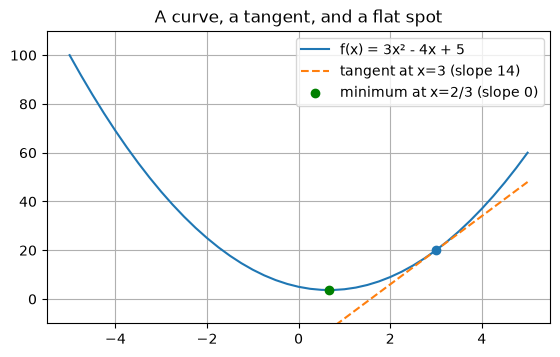

In [3]:
xs = np.arange(-5, 5.25, 0.25)
ys = f(xs)

x0 = 3.0
tangent = f(x0) + f_prime(x0) * (xs - x0)     # y = f(x0) + f'(x0)(x - x0)

plt.plot(xs, ys, label="f(x) = 3x² - 4x + 5")
plt.plot(xs, tangent, "--", label="tangent at x=3 (slope 14)")
plt.scatter([x0], [f(x0)], zorder=5)
plt.scatter([2/3], [f(2/3)], color="green", zorder=5, label="minimum at x=2/3 (slope 0)")
plt.ylim(-10, 110)
plt.legend()
plt.title("A curve, a tangent, and a flat spot")
plt.show()

### Numerical derivative: the notebook's `(f(x+h)-f(x))/h`

Two checks. At $x=3$ the exact slope is $6(3)-4=14$. At $x=\tfrac23$ the exact slope is $0$.


Taylor expansion:
$$f(x+h)=f(x)+f'(x)\,h+\tfrac12 f''(x)\,h^2+\dots
\;\Rightarrow\;
\frac{f(x+h)-f(x)}{h}=f'(x)+\underbrace{\tfrac12 f''(x)\,h}_{\text{error}}$$
Here $f''(x)=6$, so error $=3h=3\times10^{-6}$. That is exactly the `2.999e-06` you saw.

Fix: the **central difference** has error $O(h^2)$ and is *exactly* right for a quadratic:
$$f'(x)\approx\frac{f(x+h)-f(x-h)}{2h}$$

In [4]:
h = 1e-6
for x in (3.0, 2/3):
    fwd = (f(x + h) - f(x)) / h
    cen = (f(x + h) - f(x - h)) / (2*h)
    print(f"x={x:.4f}  exact={f_prime(x):.6f}  forward={fwd:.9f}  central={cen:.9f}")
    print(f"          forward error={fwd - f_prime(x):+.3e}   (predicted 3h = {3*h:.1e})")

x=3.0000  exact=14.000000  forward=14.000003002  central=14.000000002
          forward error=+3.002e-06   (predicted 3h = 3.0e-06)
x=0.6667  exact=0.000000  forward=0.000002999  central=-0.000000000
          forward error=+2.999e-06   (predicted 3h = 3.0e-06)


**Gotcha: smaller `h` is not always better.** Two errors fight each other:

* *truncation error* (the $\tfrac12 f'' h$ term) **shrinks** as `h` shrinks
* *floating-point cancellation* (subtracting two nearly-equal numbers, then dividing by a tiny `h`) **grows** as `h` shrinks

So the error is V-shaped. This is why we *never* use numerical differentiation to train networks (it is also $O(\#\text{params})$ forward passes). We use it only to **check** backprop.

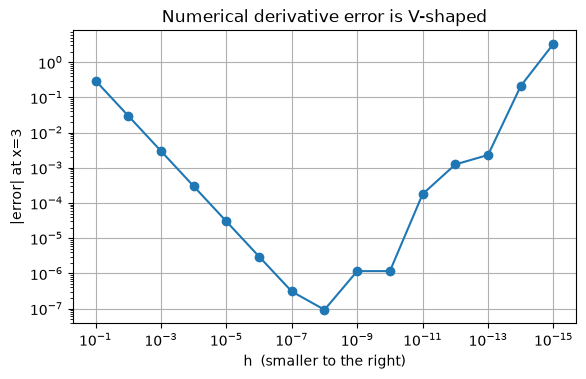

best h in this sweep: 1e-8


In [5]:
hs = 10.0 ** -np.arange(1, 16)
err = [abs((f(3 + h_) - f(3)) / h_ - 14) for h_ in hs]

plt.loglog(hs, err, "o-")
plt.gca().invert_xaxis()
plt.xlabel("h  (smaller to the right)"); plt.ylabel("|error| at x=3")
plt.title("Numerical derivative error is V-shaped")
plt.show()
print("best h in this sweep: 1e-%d" % (np.argmin(err) + 1))

---
## Part 2: Partial derivatives, many inputs, one at a time

### ELI5
Lemonade stand: `profit = cups × price + tip`. Ask three separate questions:
*what if I sell one more cup?* (changes profit by `price`), *what if I raise the price?* (changes profit by `cups`), *what if the tip goes up?* (changes profit by exactly 1).
Each question changes **one** thing and freezes the rest. That is a **partial derivative**.

### Math
$$d=a\cdot b+c,\qquad a=2,\; b=-3,\; c=10\;\Rightarrow\; d=4$$

$$\frac{\partial d}{\partial a}=b=-3 \qquad \frac{\partial d}{\partial b}=a=2 \qquad \frac{\partial d}{\partial c}=1$$

Two rules you will use forever:

| op | rule | words |
|----|------|-------|
| $x+y$ | $\partial/\partial x=1,\ \partial/\partial y=1$ | **plus passes the change straight through** |
| $x\cdot y$ | $\partial/\partial x=y,\ \partial/\partial y=x$ | **times swaps**: slope w.r.t. one input is the *other* input |



In [6]:
h = 1e-6
a, b, c = 2.0, -3.0, 10.0
d1 = a*b + c

da = ((a + h)*b + c - d1) / h
db = (a*(b + h) + c - d1) / h
dc = (a*b + (c + h) - d1) / h

print("d =", d1)
print(f"dd/da = {da:+.6f}   exact b = {b:+.1f}")
print(f"dd/db = {db:+.6f}   exact a = {a:+.1f}")
print(f"dd/dc = {dc:+.6f}   exact 1 = {1.0:+.1f}")
assert math.isclose(da, b, abs_tol=1e-4) and math.isclose(db, a, abs_tol=1e-4) and math.isclose(dc, 1, abs_tol=1e-4)

d = 4.0
dd/da = -3.000000   exact b = -3.0
dd/db = +2.000000   exact a = +2.0
dd/dc = +1.000000   exact 1 = +1.0


---
## Part 3: `Value`, the autograd node

### ELI5
Every `Value` is a **sticky note** stuck to a number. The note says:
1. my number is `data`
2. I was made from these parents (`_prev`) using this operation (`_op`)
3. **if you tell me how much the final answer cares about me (`out.grad`), I know how to tell my parents how much *they* should care** (`_backward`)

A big expression becomes a web of sticky notes. Backprop is just passing messages back along the web.

### The one rule that every operation follows
$$\texttt{child.grad}\;{+}{=}\;\underbrace{\frac{\partial\,\text{out}}{\partial\,\text{child}}}_{\text{local derivative (the op knows this)}}\;\times\;\underbrace{\frac{\partial L}{\partial\,\text{out}}}_{\texttt{out.grad (comes from the future)}}$$

An operation never needs to know about the rest of the graph. It only knows its **own** local slope. The chain rule does the gluing.

| op | forward | local derivative | what `_backward` does |
|----|---------|------------------|-----------------------|
| `a + b` | $a+b$ | $1,\ 1$ | `a.grad += out.grad`, `b.grad += out.grad` |
| `a * b` | $ab$ | $b,\ a$ | `a.grad += b.data*out.grad`, `b.grad += a.data*out.grad` |
| `a ** k` | $a^k$ | $k\,a^{k-1}$ | `a.grad += k*a.data**(k-1)*out.grad` |
| `tanh` | $t=\tanh x$ | $1-t^2$ | `a.grad += (1-t**2)*out.grad` |
| `exp` | $e^x$ | $e^x$ (= `out.data`) | `a.grad += out.data*out.grad` |

Everything else is *built from these five*:
$-a=a\cdot(-1)$ &nbsp;|&nbsp; $a-b=a+(-b)$ &nbsp;|&nbsp; $a/b=a\cdot b^{-1}$ &nbsp;|&nbsp; `__radd__`, `__rmul__` let `2*x` and `1+x` work with the plain number on the left.



In [7]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0                    # dL/d(this node); starts at 0 because we ACCUMULATE into it
        self._backward = lambda: None      # leaf nodes have nothing to pass back
        self._prev = set(_children)        # parents in the graph
        self._op = _op                     # which op created me (for drawing)
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad  += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad  += other.data * out.grad
            other.grad += self.data  * out.grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data ** other, (self,), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

    def __rmul__(self, other):   # other * self
        return self * other

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __neg__(self):           # -self
        return self * -1

    def __sub__(self, other):    # self - other
        return self + (-other)

    def __radd__(self, other):   # other + self
        return self + other

    def __rsub__(self, other):   # other - self      # ADDED
        return other + (-self)

    def __rtruediv__(self, other):  # other / self   # ADDED
        return other * self**-1

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad   # += (the lecture video had a bug here using =)
        out._backward = _backward
        return out

    def backward(self):
        # 1) order the nodes so every node comes AFTER everything it depends on
        topo, visited = [], set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        # 2) seed: dL/dL = 1, then walk in reverse, each node pushes blame to its parents
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

**Sanity test of the operators.** For each expression we compare the engine's gradient to the hand-derived one.

In [9]:
# y = (x*3 + 1)**2 / (x + 2) - 1/x      at x = 1.5   (uses +, *, **, /, rsub-style ops)
def expr(x):
    return (x*3 + 1)**2 / (x + 2) - 1 / x

xv = Value(1.5)
y = expr(xv)
y.backward()

# numerical check with central difference on plain floats
g = lambda t: (t*3 + 1)**2 / (t + 2) - 1 / t
num = (g(1.5 + 1e-6) - g(1.5 - 1e-6)) / 2e-6
print("engine grad   :", xv.grad)
print("numeric grad  :", num)
assert math.isclose(xv.grad, num, rel_tol=1e-6)

# the ADDED operators
assert (1 - Value(2.0)).data == -1.0
assert (6 / Value(2.0)).data == 3.0
print("1 - Value(2) and 6 / Value(2) now work")

engine grad   : 7.403628117913833
numeric grad  : 7.403628115465466
1 - Value(2) and 6 / Value(2) now work


---
## Part 4: Computation graph + chain rule (manual backprop)

### ELI5
Gears. Gear A turns gear B **3×** per turn. Gear B turns gear C **2×** per turn. So one turn of A turns C **3 × 2 = 6×**.
You just *multiply the ratios along the path*. That is the whole chain rule.

### Math
$$L=(a\cdot b+c)\cdot f,\qquad e=a\cdot b,\quad d=e+c,\quad L=d\cdot f$$
with $a=2,\ b=-3,\ c=10,\ f=-2\Rightarrow e=-6,\ d=4,\ L=-8$.

Chain rule to reach input $a$ (multiply local slopes along the path $L\leftarrow d\leftarrow e\leftarrow a$):
$$\frac{\partial L}{\partial a}=\frac{\partial L}{\partial d}\cdot\frac{\partial d}{\partial e}\cdot\frac{\partial e}{\partial a}=(f)\cdot(1)\cdot(b)=(-2)(1)(-3)=6$$

Work backwards from the output, one node at a time:

| node | gradient $\partial L/\partial\cdot$ | why |
|------|------|-----|
| $L$ | $1$ | $\partial L/\partial L$ |
| $f$ | $d=4$ | $L=d\cdot f$ → "times swaps" |
| $d$ | $f=-2$ | same |
| $c$ | $-2$ | $d=e+c$ → plus passes the gradient through |
| $e$ | $-2$ | same |
| $a$ | $e\text{.grad}\cdot b=(-2)(-3)=6$ | $e=a\cdot b$ |
| $b$ | $e\text{.grad}\cdot a=(-2)(2)=-4$ | same |


> `x.grad` means $\dfrac{\partial L}{\partial x}$ ("how much does the *final output* care about x"), never the reverse.

In [10]:
# ---------- helpers to LOOK at a graph ----------
def topo_order(root):
    order, seen = [], set()
    def go(v):
        if v not in seen:
            seen.add(v)
            for ch in v._prev: go(ch)
            order.append(v)
    go(root)
    return order

def print_graph(root):
    """Text version of the graph: inputs first, root last."""
    print(f"{'label':<14}{'op':<7}{'data':>12}{'grad':>12}   parents")
    for n in topo_order(root):
        parents = ", ".join(p.label or "?" for p in n._prev)
        print(f"{n.label:<14}{n._op or 'leaf':<7}{n.data:>12.4f}{n.grad:>12.4f}   {parents}")

def draw_dot(root):
    from graphviz import Digraph            # needs `pip install graphviz` + the system `dot` binary
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})   # LR = left to right
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v)); build(child)
    build(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

def show(root):
    """Draw with graphviz if available, else print a table."""
    try:
        from IPython.display import display
        display(draw_dot(root))
    except Exception as err:
        print(f"(graphviz unavailable: {type(err).__name__}) text view instead:")
        print_graph(root)

L = -8.0


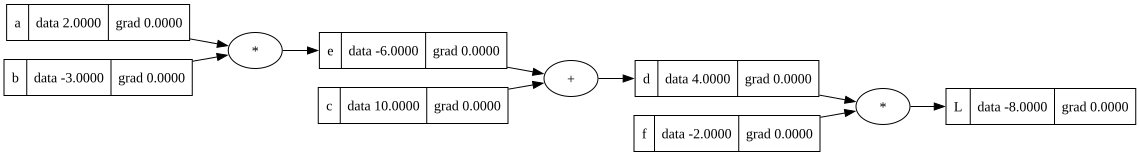

In [11]:
# ---------- build the graph (forward pass) ----------
a = Value(2.0,  label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b;  e.label = 'e'
d = e + c; d.label = 'd'
f_ = Value(-2.0, label='f')       # named f_ so we don't overwrite the function f() from Part 1
L = d * f_; L.label = 'L'
print("L =", L.data)               # -8.0
show(L)

**Manual backward pass**, one line per node, in reverse order. Compare each line to the table above.

In [12]:
L.grad  = 1.0                      # dL/dL
f_.grad = d.data                   # L = d*f   ->  dL/df = d
d.grad  = f_.data                  #           ->  dL/dd = f
c.grad  = 1.0 * d.grad             # d = e+c   ->  plus passes it through
e.grad  = 1.0 * d.grad
a.grad  = b.data * e.grad          # e = a*b   ->  times swaps
b.grad  = a.data * e.grad

print_graph(L)

label         op             data        grad   parents
b             leaf        -3.0000     -4.0000   
a             leaf         2.0000      6.0000   
e             *           -6.0000     -2.0000   b, a
c             leaf        10.0000     -2.0000   
d             +            4.0000     -2.0000   e, c
f             leaf        -2.0000      4.0000   
L             *           -8.0000      1.0000   d, f


**Verify with brute force.** Nudge each input by `h`, re-run the *forward* pass, measure how much `L` moved.
The notebook did this for `b` only (`-3.99999...`). We do all four.

In [13]:
def L_fn(a=2.0, b=-3.0, c=10.0, f=-2.0):
    return (a*b + c) * f

h = 1e-6
base = L_fn()
numeric = {
    'a': (L_fn(a=2.0 + h) - base) / h,
    'b': (L_fn(b=-3.0 + h) - base) / h,
    'c': (L_fn(c=10.0 + h) - base) / h,
    'f': (L_fn(f=-2.0 + h) - base) / h,
}
manual = {'a': a.grad, 'b': b.grad, 'c': c.grad, 'f': f_.grad}
for k in 'abcf':
    print(f"dL/d{k}:  manual={manual[k]:+.4f}   numeric={numeric[k]:+.4f}")
    assert math.isclose(manual[k], numeric[k], abs_tol=1e-3)

dL/da:  manual=+6.0000   numeric=+6.0000
dL/db:  manual=-4.0000   numeric=-4.0000
dL/dc:  manual=-2.0000   numeric=-2.0000
dL/df:  manual=+4.0000   numeric=+4.0000


### What is a gradient *for*? Take one step.
`grad` points in the direction that **increases** `L`. The notebook's `a.data += 0.05 * a.grad` therefore pushes `L` *up*.
(To *minimise* a loss you subtract, see Part 9.)

$$a\leftarrow2+0.05(6)=2.3,\quad b\leftarrow-3+0.05(-4)=-3.2,\quad c\leftarrow10+0.05(-2)=9.9,\quad f\leftarrow-2+0.05(4)=-1.8$$

$$L_{new}=(2.3\cdot(-3.2)+9.9)\cdot(-1.8)=(2.54)(-1.8)=-4.572$$

> The original notebook printed `-8.0` after this step. That means all grads were still `0` when the cell ran, i.e. it was executed in the wrong order (Part 10).

In [14]:
step = 0.05
a_n = a.data + step * a.grad
b_n = b.data + step * b.grad
c_n = c.data + step * c.grad
f_n = f_.data + step * f_.grad
print("before:", L.data, "   after one nudge:", round(L_fn(a_n, b_n, c_n, f_n), 4))
assert math.isclose(L_fn(a_n, b_n, c_n, f_n), -4.572)

before: -8.0    after one nudge: -4.572


---
## Part 5: A single neuron (tanh), manual backprop

### ELI5
A neuron is a **tiny judge**. Each input is a vote $x_i$; each weight $w_i$ says how much the judge *trusts* that voter; the bias $b$ is the judge's built-in mood.
The judge adds up trusted votes, then squashes the verdict through a **dimmer switch** (`tanh`) so the answer is always between $-1$ (firmly no) and $+1$ (firmly yes).

The dimmer is steep in the middle and **flat at both ends**. Flat means slope $\approx0$ means almost no blame flows back (this is *saturation* / vanishing gradient).

### Math
$$n=x_1w_1+x_2w_2+b,\qquad o=\tanh(n)$$

$$\tanh(x)=\frac{e^{2x}-1}{e^{2x}+1},\qquad \frac{d}{dx}\tanh x=1-\tanh^2 x$$

*Why $1-t^2$?* Let $u=e^{2x}$, $t=\frac{u-1}{u+1}$. Then $\frac{dt}{dx}=\frac{2}{(u+1)^2}\cdot2u=\frac{4u}{(u+1)^2}$ and $1-t^2=\frac{(u+1)^2-(u-1)^2}{(u+1)^2}=\frac{4u}{(u+1)^2}$. Same thing.

**Why the weird bias `6.8813735870195432`?** It is $6+\operatorname{arcsinh}(1)$: the $6$ cancels the $-6$ coming from the weighted inputs, leaving $n=\operatorname{arcsinh}(1)=0.8813735870195432$. For that $n$, $\sinh n=1,\ \cosh n=\sqrt2$, so $o=\tanh n=\tfrac1{\sqrt2}=0.7071\ldots$ and $1-o^2=\tfrac12$ exactly. The lecture chose it so the gradients are clean (halves).

| step | value |
|------|-------|
| $x_1w_1$ | $2\cdot(-3)=-6$ |
| $x_2w_2$ | $0\cdot1=0$ |
| sum | $-6$ |
| $n=\text{sum}+b$ | $0.88137\ldots$ |
| $o=\tanh n$ | $0.70710\ldots$ |

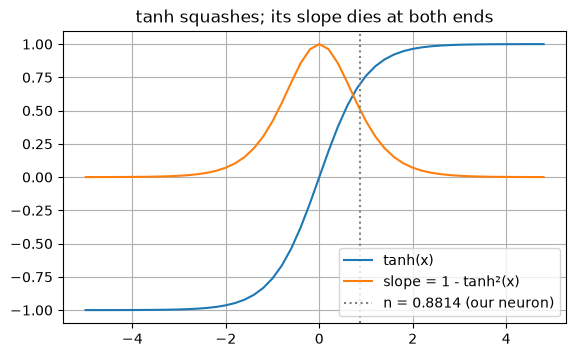

In [15]:
xs_ = np.arange(-5, 5, 0.2)
plt.plot(xs_, np.tanh(xs_), label="tanh(x)")
plt.plot(xs_, 1 - np.tanh(xs_)**2, label="slope = 1 - tanh²(x)")
plt.axvline(0.8813735870195432, color="gray", ls=":", label="n = 0.8814 (our neuron)")
plt.legend(); plt.title("tanh squashes; its slope dies at both ends"); plt.show()

n = 0.8813735870195432    o = 0.7071067811865476


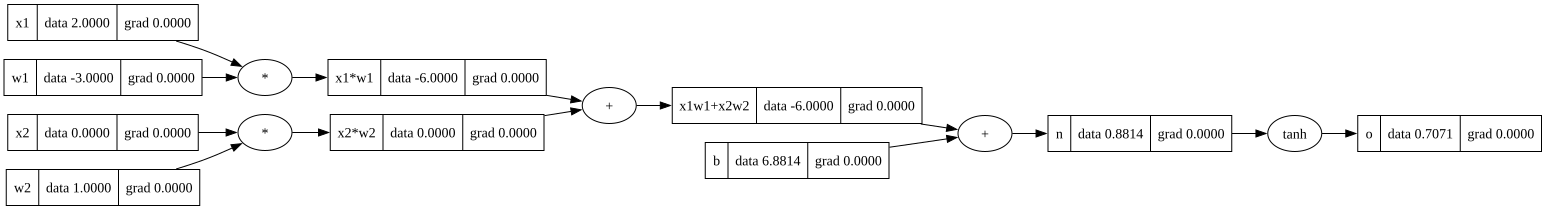

In [16]:
def make_neuron():
    x1 = Value(2.0,  label='x1');  x2 = Value(0.0, label='x2')
    w1 = Value(-3.0, label='w1');  w2 = Value(1.0, label='w2')
    b  = Value(6.8813735870195432, label='b')
    x1w1 = x1*w1;        x1w1.label = 'x1*w1'
    x2w2 = x2*w2;        x2w2.label = 'x2*w2'
    s    = x1w1 + x2w2;  s.label    = 'x1w1+x2w2'
    n    = s + b;        n.label    = 'n'
    o    = n.tanh();     o.label    = 'o'
    return dict(x1=x1, x2=x2, w1=w1, w2=w2, b=b, x1w1=x1w1, x2w2=x2w2, s=s, n=n, o=o)

N = make_neuron()
print("n =", N['n'].data, "   o =", N['o'].data)
assert math.isclose(N['o'].data, 1/math.sqrt(2))
show(N['o'])

**Manual backward, node by node.** Notice the notebook's cells for this part were shuffled; here they are in the order the math flows.

| node | gradient | reason |
|------|----------|--------|
| $o$ | $1$ | seed |
| $n$ | $1-o^2=0.5$ | tanh slope |
| $b$ | $0.5$ | $n=s+b$ → plus passes through |
| $s$ | $0.5$ | same |
| $x_1w_1$, $x_2w_2$ | $0.5$ each | $s=x_1w_1+x_2w_2$ → plus passes through |
| $x_1$ | $w_1\cdot0.5=-1.5$ | times swaps |
| $w_1$ | $x_1\cdot0.5=\ \ 1.0$ | times swaps |
| $x_2$ | $w_2\cdot0.5=\ \ 0.5$ | times swaps |
| $w_2$ | $x_2\cdot0.5=\ \ 0.0$ | **$x_2=0$: this weight has no effect** |

The last row is worth remembering: a weight multiplied by a zero input receives **zero blame**, so it cannot learn from that example.

In [17]:
N = make_neuron()
o, n, s, b = N['o'], N['n'], N['s'], N['b']
x1w1, x2w2 = N['x1w1'], N['x2w2']
x1, x2, w1, w2 = N['x1'], N['x2'], N['w1'], N['w2']

o.grad    = 1.0
n.grad    = 1 - o.data**2          # tanh slope
s.grad    = 1.0 * n.grad
b.grad    = 1.0 * n.grad
x1w1.grad = 1.0 * s.grad
x2w2.grad = 1.0 * s.grad
x1.grad   = w1.data * x1w1.grad
w1.grad   = x1.data * x1w1.grad
x2.grad   = w2.data * x2w2.grad
w2.grad   = x2.data * x2w2.grad
print_graph(o)

# compare with the automatic engine on a FRESH copy
M = make_neuron(); M['o'].backward()
for k in ('x1', 'w1', 'x2', 'w2', 'b', 'n'):
    assert math.isclose(N[k].grad, M[k].grad, abs_tol=1e-12), k
print("\nmanual == automatic for x1, w1, x2, w2, b, n")

label         op             data        grad   parents
w1            leaf        -3.0000      1.0000   
x1            leaf         2.0000     -1.5000   
x1*w1         *           -6.0000      0.5000   w1, x1
w2            leaf         1.0000      0.0000   
x2            leaf         0.0000      0.5000   
x2*w2         *            0.0000      0.5000   w2, x2
x1w1+x2w2     +           -6.0000      0.5000   x1*w1, x2*w2
b             leaf         6.8814      0.5000   
n             +            0.8814      0.5000   x1w1+x2w2, b
o             tanh         0.7071      1.0000   n

manual == automatic for x1, w1, x2, w2, b, n


### Gotcha: `grad` **accumulates**, so running backward twice doubles it
Every `_backward` uses `+=`. Your original notebook called `o.backward()` and *then*, a few cells later, `o._backward()` again, so gradients got added twice.
Verified below: `n.grad` goes `0.5 → 1.0`.

This is exactly why PyTorch has `optimizer.zero_grad()`, and why Part 9 resets `p.grad = 0.0` before every backward pass.

In [18]:
M = make_neuron()
M['o'].backward()
print("n.grad after backward()          :", round(M['n'].grad, 4))
M['o']._backward()                       # simulates re-running a cell
print("n.grad after an extra _backward():", round(M['n'].grad, 4), " <- doubled")

n.grad after backward()          : 0.5
n.grad after an extra _backward(): 1.0  <- doubled


---
## Part 6: Automatic `backward()`: order, and why `+=`

### ELI5
Blame can only be handed to a parent **after every child that used it has reported in**.
Think of a company: a manager cannot report upward until all of their direct reports have reported to them.
So we first sort the nodes so that **inputs come before the things built from them** (a *topological sort*), then walk that list **backwards**.

### The algorithm in `Value.backward`
1. `build_topo`: depth-first search; a node is appended **after** all its parents, so the list is "inputs ... output".
2. Seed `self.grad = 1.0` (because $\partial L/\partial L=1$).
3. `for node in reversed(topo): node._backward()`: output first, inputs last.

### Why `+=` and not `=` (the "bug" the notebook mentions)
Your markdown said *"a bug where neurons depend on each other"*. The real situation is: **one node is used more than once**.
If $x$ feeds into several nodes $u$, each path contributes, and contributions **add** (multivariable chain rule):
$$\frac{\partial L}{\partial x}=\sum_{u\,\in\,\text{users of }x}\frac{\partial L}{\partial u}\cdot\frac{\partial u}{\partial x}$$

*Example 1:* $b=a+a=2a\Rightarrow \partial b/\partial a=2$. With `=` the second write would overwrite the first and give 1.

*Example 2:* $f=(a\,b)(a+b)$ with $a=-2,\ b=3$. Let $d=ab=-6$, $e=a+b=1$, $f=de=-6$. Variable $a$ reaches $f$ through **two paths**:
$$\frac{\partial f}{\partial a}=\underbrace{e\cdot b}_{\text{via }d:\ 1\cdot3=3}+\underbrace{d\cdot1}_{\text{via }e:\ -6}=-3 \qquad
\frac{\partial f}{\partial b}=\underbrace{e\cdot a}_{-2}+\underbrace{d\cdot1}_{-6}=-8$$

In [19]:
# the order backward() will visit (reverse of this list), for our neuron
N = make_neuron()
print("topological order (inputs first):")
print("  " + "  ->  ".join(v.label for v in topo_order(N['o'])))
print("backward visits it in reverse, starting at 'o'.")

topological order (inputs first):
  x1  ->  w1  ->  x1*w1  ->  x2  ->  w2  ->  x2*w2  ->  x1w1+x2w2  ->  b  ->  n  ->  o
backward visits it in reverse, starting at 'o'.


b = a + a  ->  da = 2.0
f = (a*b)*(a+b) = -6.0   df/da = -3.0   df/db = -8.0


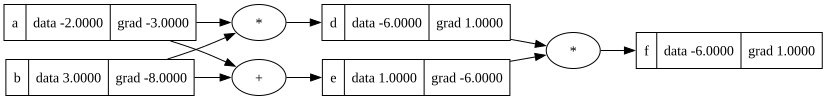

In [20]:
# Example 1: a node used twice
a = Value(3.0, label='a')
b = a + a;  b.label = 'b'
b.backward()
print("b = a + a  ->  da =", a.grad)          # 2.0
assert a.grad == 2.0

# Example 2: two paths from a to f
a = Value(-2.0, label='a')
b = Value(3.0,  label='b')
d = a * b;  d.label = 'd'
e = a + b;  e.label = 'e'
f2 = d * e; f2.label = 'f'
f2.backward()
print("f = (a*b)*(a+b) =", f2.data, "  df/da =", a.grad, "  df/db =", b.grad)
assert (f2.data, a.grad, b.grad) == (-6.0, -3.0, -8.0)
show(f2)

**Limitations of this `backward()` worth knowing**
* `build_topo` is recursive: a graph deeper than Python's recursion limit (~1000) crashes. Real frameworks use an iterative sort.
* Gradients are *not* reset between calls. If you reuse nodes, zero them first (Part 9).
* `tanh` as written calls `math.exp(2*x)`, which raises `OverflowError` for very large `x` (above ~355). Production code uses a stable formula.

---
## Part 7: tanh built from `exp`, and the PyTorch cross-check

### ELI5
Is the engine "real"? Test: take the *same* neuron but build `tanh` yourself from tiny Lego bricks (`exp`, `+`, `-`, `/`).
We never wrote a derivative for this combination, yet backprop must still give identical answers, because **the chain rule composes**.
Any function you can assemble from supported bricks gets gradients for free.

### Math
$$o=\frac{e^{2n}-1}{e^{2n}+1}=\frac{E-1}{E+1},\qquad E=e^{2n}$$
Written with the engine: `e = (2*n).exp()`, then `o = (e - 1) / (e + 1)`. This uses `__rmul__`, `exp`, `__sub__`, `__add__`, `__truediv__` (via `__pow__(-1)`).

In [21]:
x1 = Value(2.0,  label='x1');  x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1');  w2 = Value(1.0, label='w2')
b  = Value(6.8813735870195432, label='b')
n  = x1*w1 + x2*w2 + b;  n.label = 'n'

E = (2*n).exp()
o_exp = (E - 1) / (E + 1);  o_exp.label = 'o'
o_exp.backward()

print("o            :", o_exp.data)
print("grads x1,w1,x2,w2:", round(x1.grad, 6), round(w1.grad, 6), round(x2.grad, 6), round(w2.grad, 6))
ref = make_neuron(); ref['o'].backward()
assert math.isclose(o_exp.data, ref['o'].data, rel_tol=1e-12)
for k, v in (('x1', x1), ('w1', w1), ('x2', x2), ('w2', w2)):
    assert math.isclose(v.grad, ref[k].grad, abs_tol=1e-12)
print("identical to the fused tanh version")

o            : 0.7071067811865477
grads x1,w1,x2,w2: -1.5 1.0 0.5 0.0
identical to the fused tanh version


### PyTorch cross-check, and a precision trap in the original

Your PyTorch cell printed `o = 0.7071066904` and `x1.grad = -1.5000003851`, while the true values are `0.7071067812` and `-1.5` exactly.
That ~$10^{-7}$ discrepancy is **not** a backprop difference. Cause:

`torch.Tensor([6.88137358702...])` creates a **float32** tensor first (about 7 decimal digits), and `.double()` afterwards cannot recover the lost digits.
The bias is rounded before the computation even starts:

$$\Delta b\approx-1.8\times10^{-7}\;\Rightarrow\;\Delta o\approx\underbrace{(1-o^2)}_{0.5}\cdot\Delta b\approx-9.1\times10^{-8}$$

which matches `0.7071066904 - 0.7071067812 = -9.08e-08`. Fix: `torch.tensor([...], dtype=torch.double)`.

In [22]:
# reproduce the float32 loss of precision WITHOUT torch (numpy float32 == torch.float32)
b64 = 6.8813735870195432
b32 = float(np.float32(b64))
print("b as float64:", b64)
print("b as float32:", b32, "   difference:", b32 - b64)
print("predicted change in o:", 0.5 * (b32 - b64))

o64 = math.tanh(2.0*-3.0 + 0.0*1.0 + b64)
o32 = math.tanh(2.0*-3.0 + 0.0*1.0 + b32)
print("actual change in o   :", o32 - o64)

b as float64: 6.881373587019543
b as float32: 6.881373405456543    difference: -1.8156300019001037e-07
predicted change in o: -9.078150009500519e-08
actual change in o   : -9.078151175234694e-08


In [23]:
try:
    import torch
except ImportError:
    torch = None
    print("torch not installed. Notebook's recorded outputs were:")
    print("  buggy (float32 -> double): o=0.7071066904050358  x1.grad=-1.5000003851533106  w1.grad=1.0000002567688737")

if torch is not None:
    def run(dtype_fix):
        mk = (lambda v: torch.tensor([v], dtype=torch.double, requires_grad=True)) if dtype_fix \
             else (lambda v: torch.Tensor([v]).double().requires_grad_())
        x1, x2, w1, w2, b = mk(2.0), mk(0.0), mk(-3.0), mk(1.0), mk(6.8813735870195432)
        o = torch.tanh(x1*w1 + x2*w2 + b)
        o.backward()
        return o.item(), x1.grad.item(), w1.grad.item(), x2.grad.item(), w2.grad.item()
    print("float32->double (original):", run(False))
    print("dtype=torch.double (fixed) :", run(True))
    print("our engine                 :", ref['o'].data, ref['x1'].grad, ref['w1'].grad, ref['x2'].grad, ref['w2'].grad)

float32->double (original): (0.7071066904050358, -1.5000003851533106, 1.0000002567688737, 0.5000001283844369, 0.0)
dtype=torch.double (fixed) : (0.7071067811865476, -1.4999999999999996, 0.9999999999999998, 0.4999999999999999, 0.0)
our engine                 : 0.7071067811865476 -1.4999999999999996 0.9999999999999998 0.4999999999999999 0.0


---
## Part 8: Neuron → Layer → MLP

### ELI5
* **Neuron**: one judge (Part 5).
* **Layer**: a *row* of judges who all see the same inputs but trust them differently, so each notices something different.
* **MLP**: rows in a line. Each row's verdicts become the next row's votes. The final row gives the answer.

### Math
A neuron with $n_{in}$ inputs:
$$o=\tanh\Big(\sum_{i=1}^{n_{in}}w_ix_i+b\Big)$$
In code: `sum((wi*xi for ...), self.b)`: the second argument to `sum` is the **start value**, so `b` is added first.

A layer of $n_{out}$ neurons has $n_{out}\cdot(n_{in}+1)$ parameters ($+1$ for each bias).

`MLP(3, [4, 4, 1])` means layer sizes $3\to4\to4\to1$:
$$4(3+1)+4(4+1)+1(4+1)=16+20+5=\mathbf{41}\ \text{parameters}$$

Design notes: every neuron, **including the output one**, ends in `tanh`, so outputs live in $(-1,1)$. That suits $\pm1$ targets; for general regression you would drop it on the last layer. A `Layer` with a single neuron returns a bare `Value` (`outs[0]`) instead of a list, which is why `MLP(...)(x)` gives one number.

In [24]:
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)   # w·x + b
        return act.tanh()

    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [25]:
random.seed(42)
net = MLP(3, [4, 4, 1])
x = [2.0, 3.0, -1.0]
print("output   :", net(x))
print("#params  :", len(net.parameters()))
assert len(net.parameters()) == 4*(3+1) + 4*(4+1) + 1*(4+1) == 41

out = net(x)
out.backward()
print("grad of output wrt first weight of first neuron:", net.layers[0].neurons[0].w[0].grad)

output   : Value(data=0.6994093620224068)
#params  : 41
grad of output wrt first weight of first neuron: -0.018429380934491063


---
## Part 9: The training loop

### ELI5
You are blindfolded on a hilly field and want the lowest point. You can only feel the slope under your feet.
Strategy: feel the slope, **take a small step downhill**, repeat. The field is the **loss** (how wrong the network is), your position is the 41 weights, the slope is the gradient, and the step size is the **learning rate** $\eta$.

### Math
Data: 4 examples, 3 features each, desired outputs $\pm1$. Loss = sum of squared errors:
$$L=\sum_{i=1}^{4}(\hat y_i-y_i)^2,\qquad \frac{\partial L}{\partial\hat y_i}=2(\hat y_i-y_i)$$

Backprop pushes that signal down to every parameter $p$, then we step **against** the gradient (downhill):
$$p\;\leftarrow\;p-\eta\,\frac{\partial L}{\partial p},\qquad \eta=0.1$$

**The 4-step recipe (memorise the order):**
1. **Forward**: compute predictions and loss
2. **Zero grads**: `p.grad = 0.0` for every parameter (because `+=` accumulates!)
3. **Backward**: `loss.backward()`
4. **Update**: `p.data += -lr * p.grad`

In [26]:
xs_data = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys_data = [1.0, -1.0, -1.0, 1.0]       # desired targets


def train(steps=20, lr=0.1, zero_grad=True, seed=1, verbose=False):
    random.seed(seed)
    net = MLP(3, [4, 4, 1])
    losses = []
    for k in range(steps):
        # 1) forward
        ypred = [net(x) for x in xs_data]
        loss = sum((yout - ygt)**2 for ygt, yout in zip(ys_data, ypred))

        # 2) zero grads
        if zero_grad:
            for p in net.parameters():
                p.grad = 0.0

        # 3) backward
        loss.backward()

        # 4) update (gradient DESCENT: minus sign)
        for p in net.parameters():
            p.data += -lr * p.grad

        losses.append(loss.data)
        if verbose:
            print(k, loss.data)
    return net, losses

net, losses = train(verbose=True)
print("\npredictions:", [round(net(x).data, 3) for x in xs_data])
print("targets    :", ys_data)

0 6.24427205907587
1 3.73966564311874
2 1.8754136694045762
3 1.335743071898591
4 1.3966501498813333
5 1.5807022112577909
6 0.06172970774391842
7 0.030653218966724995
8 0.024007997900144365
9 0.02044122098033727
10 0.018111550964663416
11 0.016425794508245592
12 0.015125680469293298
13 0.014078512660737738
14 0.013208295707222546
15 0.012467977808585048
16 0.011826649455638286
17 0.011263033587174887
18 0.010761917918428118
19 0.010312079744954308

predictions: [0.953, -0.937, -0.976, 0.944]
targets    : [1.0, -1.0, -1.0, 1.0]


**Reading this:** the loss starts around 6 and falls to ~0.01 in 20 steps; predictions land close to the $\pm1$ targets.
Note the curve is **not monotonic**: it creeps *up* over steps 3 to 5 (1.34 → 1.40 → 1.58) and then collapses to 0.06 at step 6. A fixed step size on a curved loss can overshoot a little before settling; "loss must fall every step" is false.

> **Why the original shows a loss of `0.019` at step 0:** that cell was re-run on a network that had *already been trained*, so the learning story (large loss falling) is invisible in the saved output. Here the net is re-created with a fixed seed so you can see it.
> Exact numbers differ from yours because the random initial weights differ, but the shape of the curve is the same.

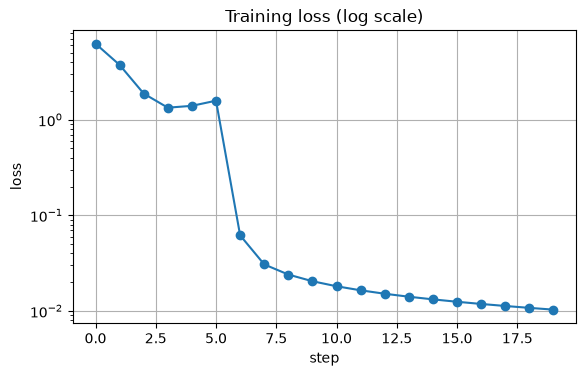

In [27]:
plt.plot(losses, "o-")
plt.xlabel("step"); plt.ylabel("loss"); plt.yscale("log")
plt.title("Training loss (log scale)"); plt.show()

### Experiments: break it on purpose
Three runs from the same initial weights. Predict first, then look.

1. **Healthy**: `lr=0.1`, zero grads each step.
2. **Tiny learning rate**: `lr=0.001`. Safe but slow.
3. **Forgot `zero_grad`**: gradients pile up across steps, so each step uses the *sum of all past gradients*.

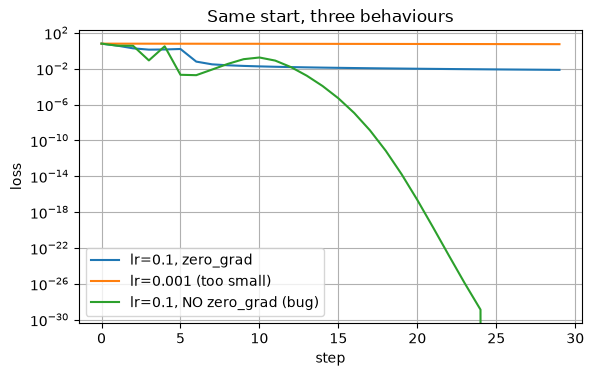

final loss  healthy=0.0074   slow=5.4539   no_zero_grad=0


In [28]:
_, healthy  = train(steps=30, lr=0.1)
_, slow     = train(steps=30, lr=0.001)
_, no_zero  = train(steps=30, lr=0.1, zero_grad=False)

plt.plot(healthy, label="lr=0.1, zero_grad")
plt.plot(slow,    label="lr=0.001 (too small)")
plt.plot(no_zero, label="lr=0.1, NO zero_grad (bug)")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss"); plt.legend()
plt.title("Same start, three behaviours"); plt.show()

print(f"final loss  healthy={healthy[-1]:.4f}   slow={slow[-1]:.4f}   no_zero_grad={no_zero[-1]:.4g}")

**Surprise: the "buggy" run did not fail on this seed.** It reached a *lower* loss than the healthy run. Do not conclude that skipping `zero_grad` is fine. Run it on several seeds:

In [29]:
print(f"{'seed':>4}  {'healthy final loss':>20}  {'no zero_grad final loss':>25}")
for seed in range(8):
    _, h_ = train(steps=30, lr=0.1, seed=seed)
    _, z_ = train(steps=30, lr=0.1, zero_grad=False, seed=seed)
    flag = "   <-- stuck" if z_[-1] > 1 else ""
    print(f"{seed:>4}  {h_[-1]:>20.4g}  {z_[-1]:>25.4g}{flag}")

seed    healthy final loss    no zero_grad final loss
   0               0.01182                          0
   1              0.007411                          0
   2               0.01246                  1.877e-11
   3               0.01038                          8   <-- stuck
   4               0.01153                  0.0004039
   5              0.008079                  5.832e-23
   6               0.01131                  1.616e-13
   7                0.0115                  1.001e-10


**What this shows.** Without `zero_grad`, `p.grad` becomes the running sum of every past gradient, so the update behaves like **uncontrolled momentum**:

* on most seeds it reaches a loss far below the healthy run (the accumulated "velocity" keeps pushing)
* on some seeds (e.g. seed 3) it ends at a flat **8.0** and never recovers (a dead end)
* it is no longer gradient descent on your loss, so you lose any guarantee about what it does

A bug that *sometimes looks like a speed-up* is worse than one that always crashes: you won't notice it. That is the reason the 4-step recipe has an explicit zero step.

The tiny learning rate (`lr=0.001`) is the opposite failure: perfectly safe, but after 30 steps the loss has barely moved (about 5.5).

---
## Part 10: Errors and traps in your original notebook

Found by running everything and checking by hand. Ordered by how much they can mislead you.

| # | Where | What the original has | Correct | Why it matters |
|---|-------|----------------------|---------|----------------|
| 1 | Chain-rule text | `da/dL = de/dL * dd/dL * dL/dL` | $\dfrac{\partial L}{\partial a}=\dfrac{\partial L}{\partial d}\cdot\dfrac{\partial d}{\partial e}\cdot\dfrac{\partial e}{\partial a}$ | Fractions inverted and factors wrong. This is the core idea; revise from the corrected form |
| 2 | "grad of f will be `df/dL`" | reversed | `x.grad` $=\partial L/\partial x$, so grad of `f` is $\partial L/\partial f$ | Same direction mistake |
| 3 | $f(5)$ by hand | `= 55` | **60** ($75-20+5$) | Plain arithmetic slip |
| 4 | Plot text | `f(x) = 3*x^2 - 4(3) + 5` | `... - 4x + 5` | Typo (`3` instead of `x`) |
| 5 | `np.arange(-5, 5, 0.25)` | claims range $-5\ldots5$ | stops at **4.75** (end excluded) | Plot doesn't reach the $f(5)$ you computed |
| 6 | Nudge cell output | `-8.0` | `-4.572` | Printed value means grads were still 0: cell ran before backward |
| 7 | Cell order (`draw_dot(L)`, `a.grad`) | uses `L`, `a.grad` before they exist | build graph → backward → nudge | Doesn't run top to bottom. Restart & Run All fails |
| 8 | Manual-backprop cells | `o.backward()` **then** `o._backward()` `n._backward()` ... then hard-codes `0.5` | one pass, in math order (Part 5) | `+=` accumulates, so grads doubled (`n.grad` 0.5 → 1.0), and hard-coded values hid it |
| 9 | "bug where neuron dependent on each other" | wrong description | one node **used multiple times**, so gradients must **sum** (Part 6) | Wrong mental model of why `+=` exists |
| 10 | `torch.Tensor([...]).double()` | float32 then double | `torch.tensor([...], dtype=torch.double)` | Explains the `-1.5000003851` vs `-1.5` mismatch |
| 11 | Training output | starts at loss `0.019` | starts ~6 for a fresh net | Cell was re-run on a trained net, hiding the learning curve |
| 12 | `Value` class | no `__rsub__` / `__rtruediv__` | added in Part 3 | `1 - v`, `1 / v` raise `TypeError` |
| 13 | Numerical slope at $x=\tfrac23$ | `2.999e-06`, looks like "nearly 0" | expected: error $=\tfrac12f''h=3h$ | Not a bug, but explain it (Part 1) |

**Habit to take away:** after any edit, *Restart & Run All*. Notebook state that only works in one hidden execution order is the source of #6, #7 and #8.

---
## Part 11: One-page cheat sheet + self-test

### Formulas
| idea | formula |
|------|---------|
| derivative | $f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}$ |
| forward-difference error | $\frac{f(x+h)-f(x)}{h}=f'(x)+\tfrac12f''(x)h+\dots$ |
| central difference | $\frac{f(x+h)-f(x-h)}{2h}$ (error $O(h^2)$) |
| plus | $\partial(a+b)/\partial a=1$ |
| times | $\partial(ab)/\partial a=b$ |
| power | $\partial(a^k)/\partial a=ka^{k-1}$ |
| tanh | $\partial\tanh x/\partial x=1-\tanh^2x$ |
| exp | $\partial e^x/\partial x=e^x$ |
| chain rule | $\frac{\partial L}{\partial x}=\frac{\partial L}{\partial u}\frac{\partial u}{\partial x}$ |
| node used many times | $\frac{\partial L}{\partial x}=\sum_u\frac{\partial L}{\partial u}\frac{\partial u}{\partial x}$ |
| backprop rule per op | `child.grad += local_derivative * out.grad` |
| neuron | $o=\tanh(\mathbf w\cdot\mathbf x+b)$ |
| layer params | $n_{out}(n_{in}+1)$ |
| loss (SSE) | $L=\sum_i(\hat y_i-y_i)^2$ |
| gradient descent | $p\leftarrow p-\eta\,\partial L/\partial p$ |

### Self-test (try before opening the answer)

<details><summary><b>Q1.</b> Why is <code>w2.grad = 0</code> in the Part 5 neuron?</summary>

Because $x_2=0$: $\partial o/\partial w_2=(1-o^2)\cdot x_2=0.5\cdot0=0$. A weight times a zero input has no influence on the output.
</details>

<details><summary><b>Q2.</b> If <code>a</code> is used in two places, what happens with <code>=</code> instead of <code>+=</code> in <code>_backward</code>?</summary>

The second path overwrites the first, so you lose a contribution. For $b=a+a$ you'd get 1 instead of 2.
</details>

<details><summary><b>Q3.</b> What does <code>x.grad</code> mean, in one sentence?</summary>

How much the **final output** $L$ changes per unit change in $x$: $\partial L/\partial x$.
</details>

<details><summary><b>Q4.</b> Why must the topological order be reversed in <code>backward()</code>?</summary>

A node's <code>out.grad</code> must be complete (all users have added their share) before it passes blame to its parents. Reverse topological order guarantees that.
</details>

<details><summary><b>Q5.</b> Why is the update <code>p.data += -lr * p.grad</code> (minus), but the Part 4 nudge used plus?</summary>

The gradient points toward **increasing** $L$. Training wants to **decrease** the loss, so step the opposite way. Part 4 deliberately went uphill to show the gradient is the direction of increase.
</details>

<details><summary><b>Q6.</b> How many parameters in <code>MLP(2, [3, 1])</code>?</summary>

$3(2+1)+1(3+1)=9+4=13$.
</details>

In [30]:
# Q6 check + a final end-to-end regression test of the whole engine
random.seed(0)
assert len(MLP(2, [3, 1]).parameters()) == 13

# gradient check of the full MLP against finite differences on ONE weight
random.seed(7)
m = MLP(3, [4, 4, 1])
x = [0.3, -0.2, 0.9]
out = m(x); out.backward()
w = m.layers[0].neurons[0].w[0]
analytic = w.grad

h = 1e-6
w.data += h;  plus  = m(x).data
w.data -= 2*h; minus = m(x).data
w.data += h
numeric = (plus - minus) / (2*h)
print("analytic:", analytic, "  numeric:", numeric)
assert math.isclose(analytic, numeric, rel_tol=1e-5, abs_tol=1e-8)
print("backprop through the whole MLP matches finite differences")

analytic: 0.06616716325755234   numeric: 0.06616716322072058
backprop through the whole MLP matches finite differences
